In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [4]:
"""
Parseval + Macenko + Mamba Destainer for NuInsSeg (H&E, human organs only).
============================================================================

Three complementary mechanisms, each with a falsifiable job:

  PARSEVAL  ->  Energy-conserving decomposition of OD coefficients into
                STAIN and STRUCTURE sub-bands, with a closed-form per-pixel
                uncertainty map from the ambiguity term  2 m (1-m) |c|^2.
                No MC dropout, no ensembles -- uncertainty falls out of the
                inequality  ||OD||^2 = E_stain + E_struct + E_ambig.

  MACENKO   ->  Physical prior on the stain MATRIX (the 2x3 mapping from
                stain concentrations to RGB optical density). Estimated
                ONCE on a pixel pool at start-up (Macenko 2009, SVD on the
                OD plane). Used as a consistency target: the destained
                image should be the input minus a stain field whose
                principal axes match the Macenko-estimated ones.

  MAMBA     ->  Long-range mask predictor. Replaces a small CNN MaskNet
                (receptive field ~3 px at the coefficient grid). A bi-
                directional Mamba block over the flattened coefficient map
                gives each location global context, which matters because
                "is this pixel stain or structure" depends on tissue
                context many pixels away. We use a PURE-PYTORCH Mamba
                implementation (no custom CUDA kernels) so it runs on
                Kaggle/Colab without `mamba-ssm` install pain.

Dataset: NuInsSeg (Mahbod et al. 2024), H&E nuclei instance segmentation,
665 patches of 512x512 across 31 human & mouse organs. THIS SCRIPT USES
HUMAN ORGANS ONLY by default (mouse organs are skipped). The destainer is
unsupervised: it reads ONLY each organ's `tissue images/` folder and
ignores all annotation folders (label masks, mask binary, distance maps,
weighted_maps, stacked mask, etc.).

Expected layout (point --data_root at the folder holding the organ dirs):
  data_root/
      human bladder/
          tissue images/        <- the STAINED H&E images we destain
              human_bladder_01.png ...
          label masks/  mask binary/  distance maps/  ...   (all ignored)
      human brain/
          tissue images/ ...
      mouse <organ>/             <- skipped unless --include_mouse
      ...

Organs are exposed via the `center` field (an organ index), so the same
machinery used for cross-domain splits works here as a cross-ORGAN
protocol: train on a subset of organs, evaluate destaining on held-out
organs. Run NuInsSegDataset.organ_table(root) to see the index<->organ map.

Kaggle quickstart
-----------------
  # In a notebook cell, after `%run parseval_mamba_macenko.py` (or pasting):
  import argparse, torch, numpy as np, random
  from parseval_mamba_macenko import NuInsSegDataset, train, infer, visualize

  NuInsSegDataset.organ_table("/kaggle/input/<nuinsseg-root>")  # see indices

  args = argparse.Namespace(
      data_root="/kaggle/input/<nuinsseg-root>",
      humans_only=True,               # human organs only (default)
      out_dir="/kaggle/working/runs",
      image_size=128, max_patches=0,  # NuInsSeg is 512x512 -> resize to 128
      train_centers=[], test_centers=[],   # organ indices; [] = all human organs
      batch_size=16, grad_accum=4, amp=True, num_workers=2,
      n_coef=64, frame_k=4,
      mamba_d_model=64, mamba_d_state=16, mamba_d_conv=4, mamba_layers=2,
      lr=2e-4, epochs=15, save_every=3,
      lambda_macenko=0.1, macenko_pool=50000,
      infer_only=False, infer_patches=64,
      ckpt="/kaggle/working/runs/parseval_destain.pt", seed=0,
      visualize_n=8,
  )
  torch.manual_seed(0); np.random.seed(0); random.seed(0)
  train(args)
  args.infer_only = True
  infer(args)
  visualize(args, n=8)   # prints stained / destained / uncertainty inline
"""

import argparse
import math
import os
import random
import re
import sys
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.utils import make_grid, save_image

try:
    import matplotlib.pyplot as plt  # type: ignore
    _HAS_MPL = True
except Exception:
    _HAS_MPL = False


# =============================================================================
# 1. NuInsSeg dataset (multi-organ H&E, human organs only by default)
# =============================================================================
# Layout (from the NuInsSeg release, Mahbod et al. 2024):
#   root/
#       human bladder/
#           tissue images/          <- the STAINED H&E images we destain
#               human_bladder_01.png
#               ...
#           label masks/            <- annotations (ignored)
#           mask binary/            <- annotations (ignored)
#           distance maps/          <- annotations (ignored)
#           ... (many annotation subfolders, all ignored)
#       human brain/
#           tissue images/ ...
#       mouse <organ>/              <- SKIPPED unless humans_only=False
#       ... (31 organ folders total: human + mouse)
#
# There is NO metadata.csv and NO "center". The natural grouping is by
# ORGAN, which we expose through a `center` field (an organ index) -- so
# every downstream function (train/infer/visualize, the cN__ filename
# prefixing, organ filtering) works UNCHANGED. We also keep a human-readable
# organ name map.
#
# This gives a cross-ORGAN generalization protocol: train the destainer on a
# subset of organs, evaluate on held-out organs.

# Subfolder that holds the stained originals. We match case-insensitively
# and also tolerate an underscore variant ("tissue_images").
_NUINSSEG_TISSUE_SUBDIRS = ("tissue images", "tissue_images", "tissue")


class NuInsSegDataset(Dataset):
    """
    Multi-organ H&E patch dataset for NuInsSeg.

    __getitem__ returns (tensor_image, "path|center=<organ_idx>"). The
    `centers` filter, if
    provided, selects organ INDICES (0-based, in sorted organ-name order).
    Call `NuInsSegDataset.organ_table(root)` to see the index<->name map.
    """

    def __init__(self, root, image_size=96, centers=None,
                 max_patches=None, seed=0, humans_only=True):
        self.root = Path(root).expanduser().resolve()
        self.image_size = image_size
        self.humans_only = humans_only
        if not self.root.is_dir():
            raise RuntimeError(f"NuInsSeg root not found: {self.root}")

        # Discover organ folders that contain a tissue-images subdir.
        # NuInsSeg ships both human ("human bladder", ...) and mouse
        # ("mouse ...") organs. When humans_only=True (default) we keep only
        # folders whose name starts with "human".
        organ_dirs = []
        skipped_mouse = []
        for entry in sorted(self.root.iterdir()):
            if not entry.is_dir():
                continue
            if self.humans_only and not self._is_human_organ(entry.name):
                skipped_mouse.append(entry.name)
                continue
            tissue = self._find_tissue_subdir(entry)
            if tissue is not None:
                organ_dirs.append((entry.name, tissue))
        if skipped_mouse:
            print(f"[data] humans_only=True: skipped {len(skipped_mouse)} "
                  f"non-human organ folders (e.g. {skipped_mouse[:3]})")
        if not organ_dirs:
            raise RuntimeError(
                f"No {'human ' if self.humans_only else ''}organ folders with "
                f"a 'tissue images/' subdir found under {self.root}. Point "
                f"--data_root at the NuInsSeg root that contains "
                f"'human bladder/', 'human brain/', etc.")

        # Build organ_name -> index map (sorted for determinism)
        self.organ_names = [name for name, _ in organ_dirs]
        self.organ_to_idx = {name: i for i, name in enumerate(self.organ_names)}
        self.idx_to_organ = {i: name for name, i in self.organ_to_idx.items()}

        kept = set(centers) if centers else None
        if kept:
            kept_names = [self.idx_to_organ.get(i, f"?{i}") for i in sorted(kept)]
            print(f"[data] filtering to organ indices {sorted(kept)} "
                  f"= {kept_names}")

        # Enumerate (image_path, organ_idx)
        self.samples: List[Tuple[Path, int]] = []
        for name, tissue_dir in organ_dirs:
            oidx = self.organ_to_idx[name]
            if kept is not None and oidx not in kept:
                continue
            for png in sorted(tissue_dir.iterdir()):
                if png.suffix.lower() in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
                    self.samples.append((png, oidx))
        if not self.samples:
            raise RuntimeError(
                f"No tissue images found (organ filter={kept}). "
                f"Organs available: {self.organ_names}")

        print(f"[data] NuInsSeg: {len(self.samples):,} tissue images across "
              f"{len({o for _, o in self.samples})} human organs")

        rng = random.Random(seed)
        rng.shuffle(self.samples)
        if max_patches and max_patches < len(self.samples):
            self.samples = self.samples[:max_patches]
            print(f"[data] capped to {len(self.samples):,} images")

        self.tf = transforms.Compose([
            transforms.Resize((image_size, image_size), interpolation=Image.BILINEAR),
            transforms.ToTensor(),
        ])

    @staticmethod
    def _is_human_organ(folder_name: str) -> bool:
        """True if the organ folder is a HUMAN organ. NuInsSeg names them
        'human <organ>' and 'mouse <organ>'; match the 'human' prefix
        case-insensitively, tolerating '_' or '-' separators."""
        n = folder_name.strip().lower().replace("_", " ").replace("-", " ")
        return n.startswith("human ") or n == "human"

    @staticmethod
    def _find_tissue_subdir(organ_dir: Path) -> Optional[Path]:
        # Case-insensitive match against the known tissue-subdir names
        existing = {p.name.lower(): p for p in organ_dir.iterdir() if p.is_dir()}
        for cand in _NUINSSEG_TISSUE_SUBDIRS:
            if cand.lower() in existing:
                return existing[cand.lower()]
        return None

    @classmethod
    def organ_table(cls, root, image_size=96, humans_only=True):
        """Print the organ index <-> name mapping (for choosing --train/test
        organ splits) and return it as a dict."""
        ds = cls(root, image_size=image_size, humans_only=humans_only)
        print("\n[organ table] index : organ name : n_images")
        from collections import Counter
        counts = Counter(o for _, o in ds.samples)
        for i in sorted(ds.idx_to_organ):
            print(f"  {i:2d} : {ds.idx_to_organ[i]:28s} : {counts.get(i, 0)}")
        return dict(ds.idx_to_organ)

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        path, organ_idx = self.samples[idx]
        img = Image.open(path).convert("RGB")
        x = self.tf(img)
        # Reuse the "center=" key so downstream code is unchanged; here it is
        # the organ index.
        return x, f"{path}|center={organ_idx}"


# =============================================================================
# 2. Beer-Lambert
# =============================================================================
def rgb_to_od(x, eps=1e-6):
    """x in [0,1] -> optical density."""
    return -torch.log(x.clamp(min=eps))


def od_to_rgb(od):
    return torch.exp(-od.clamp(min=0.0)).clamp(0.0, 1.0)


# =============================================================================
# 3. MACENKO STAIN MATRIX (numpy, run once on a pooled pixel set)
# =============================================================================
@torch.no_grad()
def estimate_macenko_stain_matrix(loader: DataLoader,
                                  max_pixels: int = 50000,
                                  od_thresh: float = 0.15,
                                  alpha_pct: float = 1.0,
                                  device: str = "cpu") -> torch.Tensor:
    """
    Estimate the 2x3 H&E stain matrix S (rows = hematoxylin, eosin) via the
    Macenko 2009 method:
       1. Convert pixels to OD = -log(I + eps).
       2. Drop low-OD pixels (background).
       3. Project remaining OD pixels onto the plane spanned by the top-2
          right singular vectors of the OD matrix.
       4. Take the 1st and (100-1)st percentile angles in that plane as the
          two stain axes; map back to OD space => 2 stain vectors.

    Returns S as a (2, 3) torch tensor in OD space, rows normalized to unit
    L2. By convention the row with greater RED channel is EOSIN; the other
    is HEMATOXYLIN. We sort so row 0 = hematoxylin, row 1 = eosin.
    """
    pool = []
    n_needed = max_pixels
    for x, _ in loader:
        # x: (B, 3, H, W) in [0,1]
        od = -np.log(np.clip(x.numpy(), 1e-6, 1.0))   # (B,3,H,W)
        od = od.transpose(0, 2, 3, 1).reshape(-1, 3)  # (N, 3)
        mask = od.max(axis=1) > od_thresh             # drop background
        od = od[mask]
        if od.shape[0] == 0:
            continue
        pool.append(od)
        if sum(p.shape[0] for p in pool) >= n_needed:
            break
    if not pool:
        raise RuntimeError("Macenko: no above-threshold pixels in pool.")
    OD = np.concatenate(pool, axis=0)
    if OD.shape[0] > n_needed:
        idx = np.random.choice(OD.shape[0], n_needed, replace=False)
        OD = OD[idx]
    print(f"[macenko] pooled {OD.shape[0]:,} OD pixels above threshold "
          f"{od_thresh}")

    # SVD on covariance gives principal axes
    cov = np.cov(OD, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(cov)
    V = eigvecs[:, [-1, -2]]                     # top-2 components, (3, 2)
    proj = OD @ V                                # (N, 2)
    angles = np.arctan2(proj[:, 1], proj[:, 0])  # (N,)
    a_lo = np.percentile(angles, alpha_pct)
    a_hi = np.percentile(angles, 100 - alpha_pct)
    # The two extreme directions in the OD plane => stain vectors
    v_lo = V @ np.array([np.cos(a_lo), np.sin(a_lo)])
    v_hi = V @ np.array([np.cos(a_hi), np.sin(a_hi)])
    S = np.stack([v_lo, v_hi], axis=0)           # (2, 3)
    # Normalize rows
    S /= (np.linalg.norm(S, axis=1, keepdims=True) + 1e-8)
    # Sort so hematoxylin (more blue) is row 0, eosin (more red) is row 1
    if S[0, 0] > S[1, 0]:                        # row 0 has more red -> swap
        S = S[::-1].copy()
    print(f"[macenko] estimated S =\n{S}")
    return torch.tensor(S, dtype=torch.float32, device=device)


# =============================================================================
# 4. PARSEVAL-TIGHT FRAME (unchanged)
# =============================================================================
def bjorck_orthogonalize(W, iters=3):
    """W <- W (3/2 I - 1/2 W^T W). Converges to nearest semi-orthogonal."""
    for _ in range(iters):
        W = 1.5 * W - 0.5 * W @ (W.T @ W)
    return W


class ParsevalConv2d(nn.Module):
    """Non-overlapping (stride=k) conv whose flat kernel is forced
    semi-orthogonal each forward. Yields a genuinely Parseval-tight full
    operator: ||A x||^2 = ||x||^2 and synthesis(analysis(x)) = x."""

    def __init__(self, in_ch=3, out_ch=64, k=4):
        super().__init__()
        assert out_ch >= in_ch * k * k, \
            f"out_ch {out_ch} < in_ch*k*k {in_ch*k*k}"
        self.in_ch, self.out_ch, self.k = in_ch, out_ch, k
        w = torch.empty(out_ch, in_ch * k * k)
        nn.init.orthogonal_(w)
        self.weight = nn.Parameter(w)

    def _ortho_kernel(self):
        W = bjorck_orthogonalize(self.weight, iters=3)
        return W.view(self.out_ch, self.in_ch, self.k, self.k)

    def analysis(self, x):
        return F.conv2d(x, self._ortho_kernel(), stride=self.k, padding=0)

    def synthesis(self, c):
        return F.conv_transpose2d(c, self._ortho_kernel(), stride=self.k, padding=0)

    def tightness_penalty(self):
        W = bjorck_orthogonalize(self.weight, iters=3)
        I = torch.eye(W.size(1), device=W.device, dtype=W.dtype)
        return ((W.T @ W - I) ** 2).mean()


# =============================================================================
# 5. MAMBA BLOCK (fast official kernel when available; chunked pure-PyTorch fallback)
# =============================================================================
# We try mamba-ssm's selective_scan_fn first (CUDA, ~10-100x faster). If it
# isn't installed (Kaggle/Colab default), we fall back to a chunked PyTorch
# scan that processes the sequence in blocks of `_SCAN_CHUNK` steps -- much
# faster than per-step Python looping while still running on CPU.
try:
    from mamba_ssm.ops.selective_scan_interface import selective_scan_fn  # type: ignore
    _HAS_MAMBA_SSM = True
except Exception:
    _HAS_MAMBA_SSM = False

_SCAN_CHUNK = 32  # PyTorch fallback chunk size


def _pt_selective_scan(deltaA, deltaB_x, C_p):
    """
    PyTorch-only selective scan. Inputs:
        deltaA   : (B, L, d_inner, d_state)  multiplicative decay per step
        deltaB_x : (B, L, d_inner, d_state)  input contribution per step
        C_p      : (B, L, d_state)           output projection per step
    Returns:
        y        : (B, L, d_inner)
    """
    B, L, d_inner, d_state = deltaA.shape
    h = torch.zeros(B, d_inner, d_state, device=deltaA.device, dtype=deltaA.dtype)
    ys = []
    for t in range(L):
        h = deltaA[:, t] * h + deltaB_x[:, t]
        ys.append((h * C_p[:, t].unsqueeze(1)).sum(dim=-1))
    return torch.stack(ys, dim=1)


class MambaBlock(nn.Module):
    """Single Mamba (S6) block, pure-PyTorch with chunked scan. ~10x slower
    than mamba-ssm on GPU but runs anywhere, including CPU.

    NOTE on `expand`: the canonical Mamba uses expand=2 (d_inner=2*d_model).
    For our use case the Mamba is a MASK predictor over coefficient grids,
    not a generative language model -- we don't need that much state-space
    expressivity. We default to expand=1, which HALVES the size of the
    largest intermediate tensor in the scan and drops peak GPU memory by
    ~2x. If you have headroom, bump it back to 2."""

    def __init__(self, d_model, d_state=16, d_conv=4, expand=1):
        super().__init__()
        self.d_model = d_model
        self.d_state = d_state
        self.d_conv = d_conv
        self.d_inner = expand * d_model

        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(
            self.d_inner, self.d_inner, kernel_size=d_conv,
            groups=self.d_inner, padding=d_conv - 1, bias=True)
        self.x_proj = nn.Linear(self.d_inner, d_state * 2 + d_state, bias=False)
        self.dt_proj = nn.Linear(d_state, self.d_inner, bias=True)
        nn.init.uniform_(self.dt_proj.bias, math.log(0.001), math.log(0.1))
        self.dt_proj.bias.data = torch.exp(self.dt_proj.bias.data)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, x):
        B, L, _ = x.shape
        xz = self.in_proj(x); x_b, z = xz.chunk(2, dim=-1)
        x_b = x_b.transpose(1, 2)
        x_b = self.conv1d(x_b)[:, :, :L]
        x_b = F.silu(x_b).transpose(1, 2)
        x_dbl = self.x_proj(x_b)
        delta, B_p, C_p = torch.split(
            x_dbl, [self.d_state, self.d_state, self.d_state], dim=-1)
        delta = F.softplus(self.dt_proj(delta))
        A = -torch.exp(self.A_log)
        deltaA = torch.exp(delta.unsqueeze(-1) * A)
        deltaB_x = (delta.unsqueeze(-1) * B_p.unsqueeze(2)
                    * x_b.unsqueeze(-1))

        if _HAS_MAMBA_SSM and x.is_cuda:
            # Official fast CUDA path
            # selective_scan_fn signature: u, delta, A, B, C, D, z, delta_bias
            y = selective_scan_fn(
                x_b.transpose(1, 2),            # (B, d_inner, L)
                delta.transpose(1, 2),          # (B, d_inner, L)
                A,
                B_p.transpose(1, 2),            # (B, d_state, L)
                C_p.transpose(1, 2),            # (B, d_state, L)
                self.D.float(), None, None, delta_softplus=False,
            ).transpose(1, 2)                    # -> (B, L, d_inner)
        else:
            y = _pt_selective_scan(deltaA, deltaB_x, C_p)
            y = y + self.D * x_b

        y = y * F.silu(z)
        return self.out_proj(y)


class BiMambaBlock(nn.Module):
    """Bi-directional Mamba: scan forward + backward, sum. Cheap way to get
    non-causal context for 2D image data without 4-direction VMamba scans.

    `use_checkpoint=True` (default) wraps each scan direction in
    torch.utils.checkpoint, so backward recomputes activations rather than
    storing them. ~3x peak memory reduction on the scan at the cost of one
    extra forward pass per backward step."""

    def __init__(self, d_model, d_state=16, d_conv=4, use_checkpoint=True):
        super().__init__()
        self.fwd = MambaBlock(d_model, d_state, d_conv)
        self.bwd = MambaBlock(d_model, d_state, d_conv)
        self.norm = nn.LayerNorm(d_model)
        self.use_checkpoint = use_checkpoint

    def forward(self, x):
        # x: (B, L, D)
        h = self.norm(x)
        if self.use_checkpoint and self.training and x.requires_grad:
            from torch.utils.checkpoint import checkpoint
            y_f = checkpoint(self.fwd, h, use_reentrant=False)
            y_b = checkpoint(self.bwd, h.flip(1), use_reentrant=False).flip(1)
        else:
            y_f = self.fwd(h)
            y_b = self.bwd(h.flip(1)).flip(1)
        return x + y_f + y_b


# =============================================================================
# 6. MASK PREDICTOR: Mamba-based
# =============================================================================
class MambaMaskNet(nn.Module):
    """Predicts per-coefficient stain probability m in [0,1] using Mamba
    blocks over the flattened coefficient grid. The flattening is row-major
    (raster); BiMambaBlock makes it effectively non-causal."""
    def __init__(self, n_coef, d_model=128, n_layers=2, d_state=16, d_conv=4):
        super().__init__()
        self.in_proj = nn.Linear(n_coef, d_model)
        self.blocks = nn.ModuleList([
            BiMambaBlock(d_model, d_state, d_conv) for _ in range(n_layers)
        ])
        self.out_norm = nn.LayerNorm(d_model)
        self.out_proj = nn.Linear(d_model, n_coef)

    def forward(self, c):
        # c: (B, C, H, W)  ->  (B, H*W, C)
        B, C, H, W = c.shape
        x = c.permute(0, 2, 3, 1).reshape(B, H * W, C)
        x = self.in_proj(x)
        for blk in self.blocks:
            x = blk(x)
        x = self.out_norm(x)
        m = torch.sigmoid(self.out_proj(x))            # (B, H*W, C)
        return m.reshape(B, H, W, C).permute(0, 3, 1, 2)


# =============================================================================
# 7. FULL DESTAINER
# =============================================================================
class ParsevalMambaDestainer(nn.Module):
    def __init__(self, in_ch=3, n_coef=64, k=4,
                 mamba_d_model=128, mamba_layers=2,
                 mamba_d_state=16, mamba_d_conv=4):
        super().__init__()
        assert n_coef >= in_ch * k * k
        self.k = k
        self.frame = ParsevalConv2d(in_ch, n_coef, k=k)
        self.mask = MambaMaskNet(n_coef, d_model=mamba_d_model,
                                 n_layers=mamba_layers,
                                 d_state=mamba_d_state, d_conv=mamba_d_conv)

    def forward(self, x_rgb):
        od = rgb_to_od(x_rgb)                          # (B, 3, H, W)
        c = self.frame.analysis(od)                    # (B, C, H', W')
        m = self.mask(c)                               # (B, C, H', W')

        c_stain  = m * c
        c_struct = (1.0 - m) * c
        od_stain  = self.frame.synthesis(c_stain)
        od_struct = self.frame.synthesis(c_struct)

        c2 = c.pow(2)
        E_total  = c2.sum(dim=(1, 2, 3))
        E_stain  = (m.pow(2) * c2).sum(dim=(1, 2, 3))
        E_struct = ((1.0 - m).pow(2) * c2).sum(dim=(1, 2, 3))
        E_ambig  = (2.0 * m * (1.0 - m) * c2).sum(dim=(1, 2, 3))

        ambig_map = (2.0 * m * (1.0 - m) * c2).sum(dim=1, keepdim=True)
        ambig_map = F.interpolate(ambig_map, scale_factor=self.k,
                                  mode="bilinear", align_corners=False)
        amax = ambig_map.amax(dim=(2, 3), keepdim=True).clamp(min=1e-8)
        uncertainty = ambig_map / amax

        return {
            "od_in":        od,
            "od_stain":     od_stain,
            "od_struct":    od_struct,
            "x_destained":  od_to_rgb(od_struct),
            "x_full_recon": od_to_rgb(od_stain + od_struct),
            "x_stain":      od_to_rgb(od_stain),
            "mask":         m,
            "uncertainty":  uncertainty,
            "E_total":  E_total, "E_stain": E_stain,
            "E_struct": E_struct, "E_ambig": E_ambig,
        }


# =============================================================================
# 8. LOSSES
# =============================================================================
def total_variation(x):
    return ((x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean()
            + (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean())


def chroma_penalty(x):
    mean = x.mean(dim=1, keepdim=True)
    return ((x - mean) ** 2).mean()


def macenko_consistency_loss(od_stain: torch.Tensor,
                             S_ref: torch.Tensor,
                             od_thresh: float = 0.05) -> torch.Tensor:
    """
    The destained branch's stain-OD field, od_stain (B, 3, H, W), should be
    expressible as C(p) * S where S is the Macenko-estimated 2x3 stain
    matrix. We compute the principal direction of the (per-image) stain OD
    pixels and penalize its deviation from the plane spanned by S_ref's
    two rows. Concretely: project each above-threshold pixel onto the
    orthogonal complement of span(S_ref) and penalize its squared norm.

    This pushes the destainer to put stain energy ONLY along
    physically-meaningful stain axes, while leaving direction freedom
    within that 2D plane (otherwise we'd be re-implementing Macenko).
    """
    B = od_stain.size(0)
    # Pixel matrix (B*N, 3)
    px = od_stain.permute(0, 2, 3, 1).reshape(-1, 3)
    keep = px.norm(dim=1) > od_thresh
    if keep.sum() < 16:
        return od_stain.sum() * 0.0  # no signal; return 0 with grad

    px = px[keep]                                # (M, 3)
    # Orthonormalize S_ref rows
    S = S_ref / (S_ref.norm(dim=1, keepdim=True) + 1e-8)   # (2, 3)
    # Gram-Schmidt to ensure orthonormal basis
    s0 = S[0]
    s1 = S[1] - (S[1] @ s0) * s0
    s1 = s1 / (s1.norm() + 1e-8)
    basis = torch.stack([s0, s1], dim=0)         # (2, 3) orthonormal
    # Project: component along basis vs residual
    comp = px @ basis.T                          # (M, 2)
    proj = comp @ basis                          # (M, 3) reconstruction
    resid = px - proj                            # (M, 3) off-plane
    return (resid ** 2).sum(dim=1).mean()


def compute_losses(out, x_rgb, model, w, S_ref=None):
    od_recon = out["od_stain"] + out["od_struct"]
    L_recon    = F.mse_loss(od_recon, out["od_in"])
    L_parseval = (out["E_total"] - out["E_stain"]
                  - out["E_struct"] - out["E_ambig"]).abs().mean()
    L_tight    = model.frame.tightness_penalty()
    L_tv       = total_variation(out["x_destained"])
    L_chroma   = chroma_penalty(out["x_destained"])
    m_mean     = out["mask"].mean()
    L_balance  = (m_mean - 0.5) ** 2

    if S_ref is not None and w.get("macenko", 0.0) > 0:
        L_macenko = macenko_consistency_loss(out["od_stain"], S_ref)
    else:
        L_macenko = torch.tensor(0.0, device=x_rgb.device)

    total = (w["recon"]    * L_recon
             + w["parseval"] * L_parseval
             + w["tight"]    * L_tight
             + w["tv"]       * L_tv
             + w["chroma"]   * L_chroma
             + w["balance"]  * L_balance
             + w["macenko"]  * L_macenko)

    logs = {
        "L_total":    total.item(),
        "L_recon":    L_recon.item(),
        "L_parseval": L_parseval.item(),
        "L_tight":    L_tight.item(),
        "L_tv":       L_tv.item(),
        "L_chroma":   L_chroma.item(),
        "L_balance":  L_balance.item(),
        "L_macenko":  L_macenko.item(),
        "mask_mean":  m_mean.item(),
    }
    return total, logs


# =============================================================================
# 9. TRAIN / INFER / VISUALIZE
# =============================================================================
def _make_dataset(root, image_size, centers, max_patches, seed,
                  humans_only=True):
    """Build the NuInsSeg dataset. Returns (tensor, 'path|center=<organ_idx>')
    so all downstream code (train/infer/visualize, cN__ filename prefixing,
    organ filtering) is unchanged."""
    return NuInsSegDataset(root=root, image_size=image_size,
                           centers=centers, max_patches=max_patches,
                           seed=seed, humans_only=humans_only)


def _build_dataset(args, centers=None, max_patches=None, seed=0):
    return _make_dataset(
        root=args.data_root, image_size=args.image_size, centers=centers,
        max_patches=max_patches if max_patches is not None else args.max_patches,
        seed=seed, humans_only=getattr(args, "humans_only", True),
    )


def train(args):
    assert args.image_size % args.frame_k == 0
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[device] {device}")

    train_centers = args.train_centers if args.train_centers else None
    ds = _build_dataset(args, centers=train_centers, seed=args.seed)
    dl = DataLoader(ds, batch_size=args.batch_size, shuffle=True,
                    num_workers=args.num_workers, drop_last=True,
                    persistent_workers=args.num_workers > 0,
                    pin_memory=torch.cuda.is_available())

    # --- Macenko: estimate stain matrix on a pool of training pixels -------
    # We use a small DataLoader for the pool to avoid loading everything.
    if args.lambda_macenko > 0:
        pool_dl = DataLoader(ds, batch_size=64, shuffle=True,
                             num_workers=args.num_workers)
        S_ref = estimate_macenko_stain_matrix(
            pool_dl, max_pixels=args.macenko_pool, device=device)
    else:
        S_ref = None

    model = ParsevalMambaDestainer(
        in_ch=3, n_coef=args.n_coef, k=args.frame_k,
        mamba_d_model=args.mamba_d_model,
        mamba_layers=args.mamba_layers,
        mamba_d_state=args.mamba_d_state, mamba_d_conv=args.mamba_d_conv,
    ).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"[model] {n_params/1e6:.2f}M params  "
          f"(d_model={args.mamba_d_model}, layers={args.mamba_layers}, "
          f"d_state={args.mamba_d_state})")

    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=args.epochs)

    # Automatic mixed precision: halves activation memory for the Mamba scan
    # and the conv layers, with no math change in fp32 reduction sums.
    use_amp = args.amp and torch.cuda.is_available()
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    amp_dtype = torch.float16
    print(f"[amp] enabled={use_amp}, dtype={amp_dtype}, "
          f"grad_accum={args.grad_accum}")

    weights = {
        "recon": 1.0, "parseval": 0.5, "tight": 0.1, "tv": 0.05,
        "chroma": 0.4, "balance": 0.05,
        "macenko": args.lambda_macenko,
    }

    out_dir = Path(args.out_dir); out_dir.mkdir(parents=True, exist_ok=True)

    for epoch in range(args.epochs):
        model.train()
        running, n_seen = {}, 0
        opt.zero_grad(set_to_none=True)
        for step, (x, _) in enumerate(dl):
            x = x.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", dtype=amp_dtype, enabled=use_amp):
                out = model(x)
                loss, logs = compute_losses(out, x, model, weights, S_ref=S_ref)
                loss = loss / args.grad_accum

            scaler.scale(loss).backward()

            if (step + 1) % args.grad_accum == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)

            for k, v in logs.items():
                running[k] = running.get(k, 0.0) + v
            n_seen += 1
        sched.step()
        msg = " | ".join(f"{k}={v/max(1,n_seen):.4f}" for k, v in running.items())
        print(f"[epoch {epoch+1:03d}/{args.epochs}] {msg}")

        if (epoch + 1) % args.save_every == 0 or epoch == args.epochs - 1:
            ckpt = out_dir / "parseval_destain.pt"
            torch.save({"model": model.state_dict(), "args": vars(args),
                        "S_ref": S_ref.cpu().numpy() if S_ref is not None else None},
                       ckpt)
            _dump_grid(model, ds, device, out_dir, epoch + 1, n=8)
    print(f"[done] checkpoint -> {out_dir/'parseval_destain.pt'}")


@torch.no_grad()
def _dump_grid(model, ds, device, out_dir, tag, n=8):
    model.eval()
    n = min(n, len(ds))
    xs = torch.stack([ds[i][0] for i in range(n)]).to(device)
    out = model(xs)
    unc = out["uncertainty"].repeat(1, 3, 1, 1)
    grid = torch.cat([xs, out["x_destained"], out["x_stain"], unc], dim=0)
    save_image(grid, out_dir / f"samples_epoch{tag}.png", nrow=n)


@torch.no_grad()
def infer(args):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(args.ckpt, map_location=device, weights_only=False)
    saved = ckpt["args"]
    model = ParsevalMambaDestainer(
        in_ch=3, n_coef=saved["n_coef"], k=saved.get("frame_k", 4),
        mamba_d_model=saved.get("mamba_d_model", 64),
        mamba_layers=saved.get("mamba_layers", 2),
        mamba_d_state=saved.get("mamba_d_state", 16),
        mamba_d_conv=saved.get("mamba_d_conv", 4),
    ).to(device)
    model.load_state_dict(ckpt["model"])
    model.eval()

    test_centers = args.test_centers if args.test_centers else None
    cap = args.infer_patches if args.infer_patches > 0 else None
    ds = _make_dataset(
        root=args.data_root, image_size=saved["image_size"],
        centers=test_centers, max_patches=cap, seed=args.seed,
        humans_only=saved.get("humans_only", getattr(args, "humans_only", True)))
    dl = DataLoader(ds, batch_size=args.batch_size, shuffle=False,
                    num_workers=args.num_workers,
                    pin_memory=torch.cuda.is_available())

    out_root = Path(args.out_dir) / "destained"
    in_root  = Path(args.out_dir) / "stained"
    unc_root = Path(args.out_dir) / "uncertainty"
    for r in (out_root, in_root, unc_root):
        r.mkdir(parents=True, exist_ok=True)

    counter = 0
    for x, infos in dl:
        x = x.to(device)
        out = model(x)
        for j in range(x.size(0)):
            center, src = -1, ""
            for tok in infos[j].split("|"):
                if tok.startswith("center="):
                    try: center = int(tok.split("=")[1])
                    except ValueError: pass
                else:
                    src = tok
            stem = Path(src).stem if src else f"sample_{counter:06d}"
            stem = f"c{center}__{stem}"
            save_image(x[j],                  in_root  / f"{stem}.png")
            save_image(out["x_destained"][j], out_root / f"{stem}.png")
            save_image(out["uncertainty"][j], unc_root / f"{stem}.png")
            counter += 1
    print(f"[infer] wrote {counter} destained patches -> {out_root}")


@torch.no_grad()
def visualize(args, n: int = 8, save_path: Optional[str] = None,
              max_batch: int = 4):
    """
    Load the checkpoint, destain n patches (respecting test_centers if set),
    and DISPLAY them inline as a matplotlib grid:
        row 0 = stained input,  row 1 = destained,  row 2 = uncertainty.

    Prints progress at each stage so it never looks silently hung. Runs the
    model forward in chunks of `max_batch` to bound memory and give
    incremental feedback. Always writes a PNG to `save_path` (default
    <out_dir>/viz.png) so you get output even if the notebook's matplotlib
    backend can't render inline.
    """
    if not _HAS_MPL:
        raise RuntimeError("matplotlib not available; install matplotlib.")

    # Force an inline-capable backend if we're in a notebook. If a previous
    # cell set 'Agg' (non-interactive), plt.show() would silently no-op.
    import matplotlib
    try:
        get_ipython  # type: ignore  # noqa
        in_notebook = True
    except NameError:
        in_notebook = False
    if in_notebook and matplotlib.get_backend().lower() == "agg":
        try:
            matplotlib.use("module://matplotlib_inline.backend_inline")
            print("[viz] switched matplotlib backend to inline")
        except Exception:
            print("[viz] WARNING: backend is 'Agg' (non-interactive); "
                  "inline display may not work, but PNG will be saved.")

    if save_path is None:
        save_path = str(Path(args.out_dir) / "viz.png")

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[viz] device = {device}")
    print(f"[viz] loading checkpoint: {args.ckpt}")
    ckpt = torch.load(args.ckpt, map_location=device, weights_only=False)
    saved = ckpt["args"]
    model = ParsevalMambaDestainer(
        in_ch=3, n_coef=saved["n_coef"], k=saved.get("frame_k", 4),
        mamba_d_model=saved.get("mamba_d_model", 64),
        mamba_layers=saved.get("mamba_layers", 2),
        mamba_d_state=saved.get("mamba_d_state", 16),
        mamba_d_conv=saved.get("mamba_d_conv", 4),
    ).to(device)
    model.load_state_dict(ckpt["model"])
    model.eval()
    if device.type == "cpu":
        print("[viz] NOTE: running on CPU -- the pure-PyTorch Mamba scan is "
              "slow here (~4s/patch). Use a GPU runtime, or reduce n.")

    test_centers = args.test_centers if args.test_centers else None
    ds = _make_dataset(
        root=args.data_root, image_size=saved["image_size"],
        centers=test_centers, max_patches=n * 4, seed=args.seed,
        humans_only=saved.get("humans_only", getattr(args, "humans_only", True)))
    n = min(n, len(ds))
    xs = torch.stack([ds[i][0] for i in range(n)]).to(device)

    # Chunked forward with progress so it never looks hung
    print(f"[viz] running destainer forward on {n} patches "
          f"(chunks of {max_batch}) ...")
    dest_list, unc_list = [], []
    for start in range(0, n, max_batch):
        chunk = xs[start:start + max_batch]
        out = model(chunk)
        dest_list.append(out["x_destained"].cpu())
        unc_list.append(out["uncertainty"].cpu())
        print(f"[viz]   processed {min(start + max_batch, n)}/{n}")
    destained = torch.cat(dest_list, dim=0)
    uncertainty = torch.cat(unc_list, dim=0).repeat(1, 3, 1, 1)
    stained = xs.cpu()

    print("[viz] rendering grid ...")
    fig, axes = plt.subplots(3, n, figsize=(2 * n, 6.5))
    if n == 1:
        axes = axes.reshape(3, 1)
    row_titles = ["Stained input", "Destained", "Uncertainty"]
    panels = [stained, destained, uncertainty]
    for row in range(3):
        for col in range(n):
            img = np.clip(panels[row][col].permute(1, 2, 0).numpy(), 0, 1)
            ax = axes[row, col]
            ax.imshow(img)
            ax.set_xticks([]); ax.set_yticks([])  # hide ticks but KEEP axis
            if col == 0:
                # set_ylabel works only if the axis is visible; we kept it
                ax.set_ylabel(row_titles[row], fontsize=11, rotation=90,
                              labelpad=8)
    fig.suptitle(f"Parseval + Macenko + Mamba destainer "
                 f"(centers={test_centers or 'all'})", fontsize=12)
    plt.tight_layout()

    # ALWAYS save, so there is output even if inline rendering fails
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    print(f"[viz] saved figure -> {save_path}")
    try:
        plt.show()
    except Exception as e:
        print(f"[viz] plt.show() failed ({e}); open the saved PNG instead.")
    plt.close(fig)
    print("[viz] done.")


# =============================================================================
# 10. CLI
# =============================================================================
def _parse_int_list(s):
    return [int(t) for t in s.split(",") if t.strip()] if s else []


def parse_args(argv: Optional[List[str]] = None):
    """CLI; pass `argv` explicitly when calling from a notebook."""
    p = argparse.ArgumentParser()
    p.add_argument("--data_root", type=str, required=True,
                   help="NuInsSeg root: the folder containing the organ "
                        "subfolders ('human bladder/', 'human brain/', ...).")
    p.add_argument("--include_mouse", dest="humans_only", action="store_false",
                   default=True,
                   help="Include mouse organs too. Default: human organs only.")
    p.add_argument("--out_dir", type=str, default="/kaggle/working/runs")
    # NuInsSeg images are 512x512. We resize to image_size; it must be
    # divisible by frame_k. 128/4 = 32 -> Mamba sequence length L=1024 (ok).
    # Going to 256 quadruples L (=4096) and is only advisable with the
    # mamba-ssm CUDA kernel on a strong GPU.
    p.add_argument("--image_size", type=int, default=128)
    p.add_argument("--max_patches", type=int, default=0)
    # `train_centers` / `test_centers` here are ORGAN INDICES (0-based, in
    # sorted human-organ-name order). Use NuInsSegDataset.organ_table(root)
    # to print the index<->organ map. Leave empty to use all human organs.
    p.add_argument("--train_centers", type=_parse_int_list, default=[])
    p.add_argument("--test_centers", type=_parse_int_list, default=[])
    # Memory-sensitive defaults for the pure-PyTorch Mamba scan. At
    # image_size=128, frame_k=4, mamba_d_model=64: dominant tensor is
    # (B, L=1024, d_inner=64, d_state=16). batch_size=16 + checkpointing +
    # fp16 fits a Kaggle T4 (16GB) comfortably.
    p.add_argument("--batch_size", type=int, default=16)
    p.add_argument("--grad_accum", type=int, default=4,
                   help="Gradient accumulation steps (effective batch = "
                        "batch_size * grad_accum).")
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--n_coef", type=int, default=64)
    p.add_argument("--frame_k", type=int, default=4)
    p.add_argument("--mamba_d_model", type=int, default=64,
                   help="Mamba hidden width. Halve to 32 if still OOM.")
    p.add_argument("--mamba_layers", type=int, default=2)
    p.add_argument("--mamba_d_state", type=int, default=16)
    p.add_argument("--mamba_d_conv", type=int, default=4)
    p.add_argument("--amp", action="store_true", default=True,
                   help="Mixed precision training (fp16). On by default.")
    p.add_argument("--no_amp", dest="amp", action="store_false")
    p.add_argument("--lambda_macenko", type=float, default=0.1)
    p.add_argument("--macenko_pool", type=int, default=50000)
    p.add_argument("--lr", type=float, default=2e-4)
    p.add_argument("--epochs", type=int, default=15,
                   help="NuInsSeg has only ~500 human tissue images, so use "
                        "more epochs than for a large patch dataset.")
    p.add_argument("--save_every", type=int, default=3)
    p.add_argument("--infer_only", action="store_true")
    p.add_argument("--infer_patches", type=int, default=64)
    p.add_argument("--ckpt", type=str,
                   default="/kaggle/working/runs/parseval_destain.pt")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--visualize_n", type=int, default=8)
    return p.parse_args(argv)


def main(argv: Optional[List[str]] = None):
    args = parse_args(argv)
    torch.manual_seed(args.seed); np.random.seed(args.seed); random.seed(args.seed)
    if args.infer_only:
        infer(args)
    else:
        train(args)


if __name__ == "__main__" and "ipykernel" not in sys.modules:
    main()

[data] humans_only=True: skipped 8 non-human organ folders (e.g. ['mouse fat (white and brown)_subscapula', 'mouse femur', 'mouse heart'])
[data] NuInsSeg: 472 tissue images across 23 human organs

[organ table] index : organ name : n_images
   0 : human bladder                : 12
   1 : human brain                  : 12
   2 : human cardia                 : 12
   3 : human cerebellum             : 12
   4 : human epiglottis             : 11
   5 : human jejunum                : 10
   6 : human kidney                 : 11
   7 : human liver                  : 40
   8 : human lung                   : 11
   9 : human melanoma               : 12
  10 : human muscle                 : 9
  11 : human oesophagus             : 47
  12 : human pancreas               : 44
  13 : human peritoneum             : 12
  14 : human placenta               : 40
  15 : human pylorus                : 12
  16 : human rectum                 : 12
  17 : human salivory gland         : 44
  18 : human spleen  

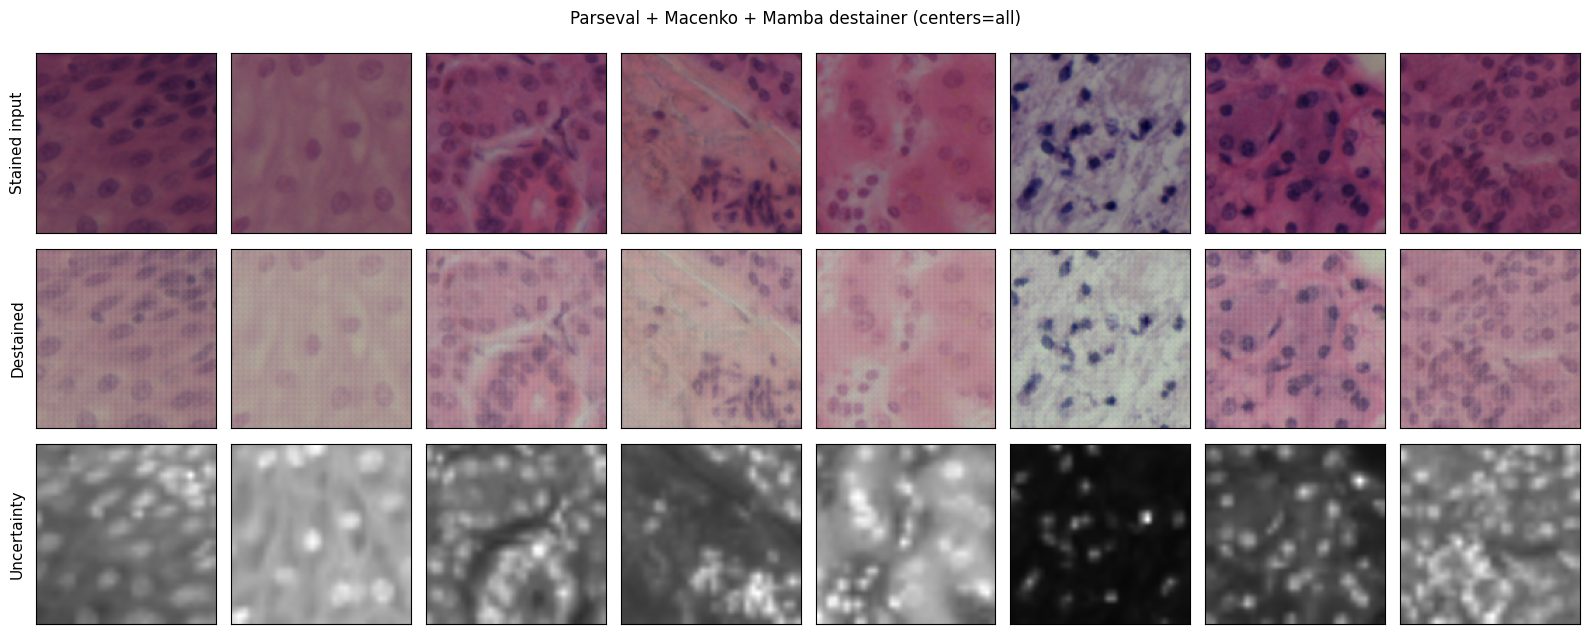

[viz] done.


In [7]:
import argparse, torch, numpy as np, random

# 1) See which organ index maps to which organ (human only):
NuInsSegDataset.organ_table("/kaggle/input/datasets/ipateam/nuinsseg")

# 2) Configure (point data_root at the folder holding 'human bladder/' etc.)
args = argparse.Namespace(
    data_root="/kaggle/input/datasets/ipateam/nuinsseg",
    humans_only=True,                  # mouse organs skipped
    out_dir="/kaggle/working/runs",
    image_size=128, max_patches=0,
    train_centers=[], test_centers=[], # organ indices; [] = all human organs
    batch_size=16, grad_accum=4, amp=True, num_workers=0,
    n_coef=64, frame_k=4,
    mamba_d_model=64, mamba_layers=2, mamba_d_state=16, mamba_d_conv=4,
    lambda_macenko=0.1, macenko_pool=50000,
    lr=2e-4, epochs=15, save_every=3,
    infer_only=False, infer_patches=64,
    ckpt="/kaggle/working/runs/parseval_destain.pt", seed=0, visualize_n=8,
)
torch.manual_seed(0); np.random.seed(0); random.seed(0)

# The functions are already in memory, so these will work:
train(args)

args.infer_only = True
infer(args)            # writes stained/, destained/, uncertainty/ PNGs
visualize(args, n=8)   # prints the grid inline

In [8]:
import shutil
from IPython.display import FileLink

# 1. Zip the contents of the /kaggle/working/runs directory
# shutil.make_archive(base_name, format, root_dir)
shutil.make_archive('/kaggle/working/runs', 'zip', '/kaggle/working/runs')

print("Zipping complete! Click the link below to download:")

# 2. Generate a clickable link to download the file directly from the cell output
FileLink(r'runs.zip')

Zipping complete! Click the link below to download:


/kaggle/working/runs.zip

In [1]:
"""
FFT-Parseval + Macenko-Projection + Mamba Destainer for NuInsSeg (H&E, human).
==============================================================================

Frequency-domain reformulation. Instead of a learned Parseval-tight conv
frame, we use the 2D FFT, which is unitary -> Parseval's identity holds
EXACTLY and for free:   sum_n |x[n]|^2  =  sum_k |X[k]|^2  (norm="ortho").
No Bjorck orthogonalization, no tightness penalty.

Key design point: stain vs structure is NOT separable by spatial frequency
alone (hematoxylin is densest exactly at nuclei, which are also the high-
frequency edges). So we factor the problem:

  COLOR separation  -> MACENKO. Estimate the 2x3 H&E stain matrix S (SVD on
                       the OD plane), then PROJECT OD onto H and E
                       concentration channels: C = OD @ pinv(S). Stain lives
                       in color space, so we separate it there.
  ENERGY bookkeeping -> FFT. Transform each concentration channel. Parseval
                       exact. We use rfft2/irfft2 so the masked spectrum stays
                       conjugate-symmetric and the inverse returns real.
  SPECTRAL selection -> MAMBA. A bi-directional Mamba predicts a soft mask
                       m[k] over the rfft2 coefficients, deciding keep
                       (structure) vs suppress (stain). Ambiguity term
                       2 m (1-m) |X|^2 is the closed-form uncertainty.
  RECONSTRUCT        -> irfft2 the kept spectrum, recombine channels via S,
                       OD -> RGB.

Dataset: NuInsSeg, human organs only (mouse skipped). Reads only each organ's
`tissue images/` folder; ignores all annotation folders.
Dependencies: pip install torch torchvision pillow numpy matplotlib
"""

import argparse
import math
import os
import random
import sys
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.utils import save_image

try:
    import matplotlib.pyplot as plt  # type: ignore
    _HAS_MPL = True
except Exception:
    _HAS_MPL = False

try:
    from mamba_ssm.ops.selective_scan_interface import selective_scan_fn  # type: ignore
    _HAS_MAMBA_SSM = True
except Exception:
    _HAS_MAMBA_SSM = False


# =============================================================================
# 1. NuInsSeg dataset (human organs only by default)
# =============================================================================
_NUINSSEG_TISSUE_SUBDIRS = ("tissue images", "tissue_images", "tissue")


class NuInsSegDataset(Dataset):
    """Multi-organ H&E dataset. Reads ONLY each organ's tissue-images folder
    and ignores all annotation folders. Human organs only by default.
    __getitem__ -> (tensor, "path|center=<organ_idx>")."""

    def __init__(self, root, image_size=128, centers=None,
                 max_patches=None, seed=0, humans_only=True):
        self.root = Path(root).expanduser().resolve()
        self.image_size = image_size
        self.humans_only = humans_only
        if not self.root.is_dir():
            raise RuntimeError(f"NuInsSeg root not found: {self.root}")
        organ_dirs, skipped = [], []
        for entry in sorted(self.root.iterdir()):
            if not entry.is_dir():
                continue
            if self.humans_only and not self._is_human_organ(entry.name):
                skipped.append(entry.name); continue
            tissue = self._find_tissue_subdir(entry)
            if tissue is not None:
                organ_dirs.append((entry.name, tissue))
        if skipped:
            print(f"[data] humans_only=True: skipped {len(skipped)} non-human "
                  f"folders (e.g. {skipped[:3]})")
        if not organ_dirs:
            raise RuntimeError(
                f"No {'human ' if self.humans_only else ''}organ folders with "
                f"'tissue images/' under {self.root}.")
        self.organ_names = [n for n, _ in organ_dirs]
        self.organ_to_idx = {n: i for i, n in enumerate(self.organ_names)}
        self.idx_to_organ = {i: n for n, i in self.organ_to_idx.items()}
        kept = set(centers) if centers else None
        if kept:
            names = [self.idx_to_organ.get(i, f"?{i}") for i in sorted(kept)]
            print(f"[data] filtering to organ indices {sorted(kept)} = {names}")
        self.samples = []
        for name, tdir in organ_dirs:
            oidx = self.organ_to_idx[name]
            if kept is not None and oidx not in kept:
                continue
            for png in sorted(tdir.iterdir()):
                if png.suffix.lower() in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
                    self.samples.append((png, oidx))
        if not self.samples:
            raise RuntimeError(f"No tissue images (filter={kept}). "
                               f"Organs: {self.organ_names}")
        print(f"[data] NuInsSeg: {len(self.samples):,} tissue images across "
              f"{len({o for _, o in self.samples})} human organs")
        rng = random.Random(seed); rng.shuffle(self.samples)
        if max_patches and max_patches < len(self.samples):
            self.samples = self.samples[:max_patches]
            print(f"[data] capped to {len(self.samples):,} images")
        self.tf = transforms.Compose([
            transforms.Resize((image_size, image_size), interpolation=Image.BILINEAR),
            transforms.ToTensor()])

    @staticmethod
    def _is_human_organ(name):
        n = name.strip().lower().replace("_", " ").replace("-", " ")
        return n.startswith("human ") or n == "human"

    @staticmethod
    def _find_tissue_subdir(organ_dir):
        existing = {p.name.lower(): p for p in organ_dir.iterdir() if p.is_dir()}
        for cand in _NUINSSEG_TISSUE_SUBDIRS:
            if cand.lower() in existing:
                return existing[cand.lower()]
        return None

    @classmethod
    def organ_table(cls, root, image_size=128, humans_only=True):
        ds = cls(root, image_size=image_size, humans_only=humans_only)
        from collections import Counter
        counts = Counter(o for _, o in ds.samples)
        print("\n[organ table] index : organ name : n_images")
        for i in sorted(ds.idx_to_organ):
            print(f"  {i:2d} : {ds.idx_to_organ[i]:28s} : {counts.get(i, 0)}")
        return dict(ds.idx_to_organ)

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        path, organ_idx = self.samples[idx]
        img = Image.open(path).convert("RGB")
        return self.tf(img), f"{path}|center={organ_idx}"


# =============================================================================
# 2. Beer-Lambert
# =============================================================================
def rgb_to_od(x, eps=1e-6): return -torch.log(x.clamp(min=eps))
def od_to_rgb(od): return torch.exp(-od.clamp(min=0.0)).clamp(0.0, 1.0)


# =============================================================================
# 3. Macenko stain matrix
# =============================================================================
@torch.no_grad()
def estimate_macenko_stain_matrix(loader, max_pixels=50000, od_thresh=0.15,
                                  alpha_pct=1.0, device="cpu"):
    pool = []
    for x, _ in loader:
        od = -np.log(np.clip(x.numpy(), 1e-6, 1.0))
        od = od.transpose(0, 2, 3, 1).reshape(-1, 3)
        od = od[od.max(axis=1) > od_thresh]
        if od.shape[0]:
            pool.append(od)
        if sum(p.shape[0] for p in pool) >= max_pixels:
            break
    if not pool:
        raise RuntimeError("Macenko: no above-threshold pixels.")
    OD = np.concatenate(pool, axis=0)
    if OD.shape[0] > max_pixels:
        OD = OD[np.random.choice(OD.shape[0], max_pixels, replace=False)]
    print(f"[macenko] pooled {OD.shape[0]:,} OD pixels (thresh {od_thresh})")
    cov = np.cov(OD, rowvar=False)
    _, eigvecs = np.linalg.eigh(cov)
    V = eigvecs[:, [-1, -2]]
    proj = OD @ V
    angles = np.arctan2(proj[:, 1], proj[:, 0])
    a_lo = np.percentile(angles, alpha_pct)
    a_hi = np.percentile(angles, 100 - alpha_pct)
    v_lo = V @ np.array([np.cos(a_lo), np.sin(a_lo)])
    v_hi = V @ np.array([np.cos(a_hi), np.sin(a_hi)])
    S = np.stack([v_lo, v_hi], axis=0)
    S /= (np.linalg.norm(S, axis=1, keepdims=True) + 1e-8)
    if S[0, 0] > S[1, 0]:
        S = S[::-1].copy()
    print(f"[macenko] estimated S =\n{S}")
    return torch.tensor(S, dtype=torch.float32, device=device)


# =============================================================================
# 4. Mamba block
# =============================================================================
def _pt_selective_scan(deltaA, deltaB_x, C_p):
    B, L, d_inner, d_state = deltaA.shape
    h = torch.zeros(B, d_inner, d_state, device=deltaA.device, dtype=deltaA.dtype)
    ys = []
    for t in range(L):
        h = deltaA[:, t] * h + deltaB_x[:, t]
        ys.append((h * C_p[:, t].unsqueeze(1)).sum(dim=-1))
    return torch.stack(ys, dim=1)


class MambaBlock(nn.Module):
    def __init__(self, d_model, d_state=16, d_conv=4, expand=1):
        super().__init__()
        self.d_model, self.d_state, self.d_conv = d_model, d_state, d_conv
        self.d_inner = expand * d_model
        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, d_conv,
                                groups=self.d_inner, padding=d_conv - 1, bias=True)
        self.x_proj = nn.Linear(self.d_inner, d_state * 3, bias=False)
        self.dt_proj = nn.Linear(d_state, self.d_inner, bias=True)
        nn.init.uniform_(self.dt_proj.bias, math.log(0.001), math.log(0.1))
        self.dt_proj.bias.data = torch.exp(self.dt_proj.bias.data)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, x):
        B, L, _ = x.shape
        x_b, z = self.in_proj(x).chunk(2, dim=-1)
        x_b = x_b.transpose(1, 2)
        x_b = self.conv1d(x_b)[:, :, :L]
        x_b = F.silu(x_b).transpose(1, 2)
        delta, B_p, C_p = torch.split(self.x_proj(x_b), [self.d_state] * 3, dim=-1)
        delta = F.softplus(self.dt_proj(delta))
        A = -torch.exp(self.A_log)
        deltaA = torch.exp(delta.unsqueeze(-1) * A)
        deltaB_x = delta.unsqueeze(-1) * B_p.unsqueeze(2) * x_b.unsqueeze(-1)
        if _HAS_MAMBA_SSM and x.is_cuda:
            y = selective_scan_fn(
                x_b.transpose(1, 2), delta.transpose(1, 2), A,
                B_p.transpose(1, 2), C_p.transpose(1, 2),
                self.D.float(), None, None, delta_softplus=False).transpose(1, 2)
        else:
            y = _pt_selective_scan(deltaA, deltaB_x, C_p) + self.D * x_b
        y = y * F.silu(z)
        return self.out_proj(y)


class BiMambaBlock(nn.Module):
    def __init__(self, d_model, d_state=16, d_conv=4, use_checkpoint=True):
        super().__init__()
        self.fwd = MambaBlock(d_model, d_state, d_conv)
        self.bwd = MambaBlock(d_model, d_state, d_conv)
        self.norm = nn.LayerNorm(d_model)
        self.use_checkpoint = use_checkpoint

    def forward(self, x):
        h = self.norm(x)
        if self.use_checkpoint and self.training and x.requires_grad:
            from torch.utils.checkpoint import checkpoint
            yf = checkpoint(self.fwd, h, use_reentrant=False)
            yb = checkpoint(self.bwd, h.flip(1), use_reentrant=False).flip(1)
        else:
            yf = self.fwd(h); yb = self.bwd(h.flip(1)).flip(1)
        return x + yf + yb


# =============================================================================
# 5. Spectral mask predictor
# =============================================================================
class SpectralMambaMask(nn.Module):
    def __init__(self, n_chan=2, d_model=64, n_layers=2, d_state=16, d_conv=4):
        super().__init__()
        self.n_chan = n_chan
        self.in_proj = nn.Linear(n_chan * 3, d_model)
        self.blocks = nn.ModuleList([
            BiMambaBlock(d_model, d_state, d_conv) for _ in range(n_layers)])
        self.out_norm = nn.LayerNorm(d_model)
        self.out_proj = nn.Linear(d_model, n_chan)

    def forward(self, spec):
        B, C, Hf, Wf = spec.shape
        feats = torch.cat([spec.abs(), spec.real, spec.imag], dim=1)
        x = feats.permute(0, 2, 3, 1).reshape(B, Hf * Wf, 3 * C)
        x = self.in_proj(x)
        for blk in self.blocks:
            x = blk(x)
        x = self.out_norm(x)
        m = torch.sigmoid(self.out_proj(x))
        return m.reshape(B, Hf, Wf, C).permute(0, 3, 1, 2)


# =============================================================================
# 6. Full FFT destainer
# =============================================================================
class FFTDestainer(nn.Module):
    def __init__(self, S_ref, image_size=128, mamba_d_model=64,
                 mamba_layers=2, mamba_d_state=16, mamba_d_conv=4):
        super().__init__()
        self.register_buffer("S", S_ref.clone())
        self.register_buffer("S_pinv", torch.linalg.pinv(S_ref))
        self.image_size = image_size
        self.mask = SpectralMambaMask(
            n_chan=2, d_model=mamba_d_model, n_layers=mamba_layers,
            d_state=mamba_d_state, d_conv=mamba_d_conv)

    def od_to_conc(self, od):
        # od (B,3,H,W) -> conc (B,2,H,W).  conc = S_pinv^T applied per pixel:
        # S is (2,3) [stain x rgb]; S_pinv is (3,2). conc[s] = sum_c od[c]*S_pinv[c,s]
        return torch.einsum("cs,bchw->bshw", self.S_pinv, od)

    def conc_to_od(self, conc):
        # conc (B,2,H,W) -> od (B,3,H,W).  od[c] = sum_s conc[s]*S[s,c]
        return torch.einsum("sc,bshw->bchw", self.S, conc)

    def forward(self, x_rgb):
        od = rgb_to_od(x_rgb)
        conc = self.od_to_conc(od)
        # Everything FFT-related runs in fp32 (complex FFT under fp16 autocast
        # is unsupported / unstable). The mask MLP also runs fp32 here.
        with torch.amp.autocast("cuda", enabled=False):
            conc32 = conc.float()
            X = torch.fft.rfft2(conc32, norm="ortho")   # complex64 (B,2,H,Wf)
            m = self.mask(X).float()                    # (B,2,H,Wf) in [0,1]
            X_struct = (1.0 - m) * X
            X_stain = m * X
            s = conc32.shape[-2:]
            conc_struct = torch.fft.irfft2(X_struct, s=s, norm="ortho")
            conc_stain = torch.fft.irfft2(X_stain, s=s, norm="ortho")
            ambig_img = torch.fft.irfft2((2.0 * m * (1.0 - m)) * X,
                                         s=s, norm="ortho").abs()
        od_struct = self.conc_to_od(conc_struct)
        od_stain = self.conc_to_od(conc_stain)

        Xmag2 = X.abs().pow(2)
        E_total = Xmag2.sum(dim=(1, 2, 3))
        E_stain = (m.pow(2) * Xmag2).sum(dim=(1, 2, 3))
        E_struct = ((1.0 - m).pow(2) * Xmag2).sum(dim=(1, 2, 3))
        E_ambig = (2.0 * m * (1.0 - m) * Xmag2).sum(dim=(1, 2, 3))

        ambig_img = ambig_img.sum(dim=1, keepdim=True)
        amax = ambig_img.amax(dim=(2, 3), keepdim=True).clamp(min=1e-8)
        uncertainty = ambig_img / amax

        return {"od_in": od, "conc": conc,
                "od_struct": od_struct, "od_stain": od_stain,
                "x_destained": od_to_rgb(od_struct),
                "x_stain": od_to_rgb(od_stain),
                "x_full_recon": od_to_rgb(od_struct + od_stain),
                "mask": m, "uncertainty": uncertainty,
                "E_total": E_total, "E_stain": E_stain,
                "E_struct": E_struct, "E_ambig": E_ambig}


# =============================================================================
# 7. Losses
# =============================================================================
def total_variation(x):
    return ((x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean()
            + (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean())


def chroma_penalty(x):
    return ((x - x.mean(dim=1, keepdim=True)) ** 2).mean()


def macenko_consistency_loss(od_stain, S_ref, od_thresh=0.05):
    px = od_stain.permute(0, 2, 3, 1).reshape(-1, 3)
    keep = px.norm(dim=1) > od_thresh
    if keep.sum() < 16:
        return od_stain.sum() * 0.0
    px = px[keep]
    S = S_ref / (S_ref.norm(dim=1, keepdim=True) + 1e-8)
    s0 = S[0]
    s1 = S[1] - (S[1] @ s0) * s0
    s1 = s1 / (s1.norm() + 1e-8)
    basis = torch.stack([s0, s1], dim=0)
    resid = px - (px @ basis.T) @ basis
    return (resid ** 2).sum(dim=1).mean()


def compute_losses(out, x_rgb, w, S_ref=None):
    L_recon = F.mse_loss(out["od_struct"] + out["od_stain"], out["od_in"])
    L_parseval = (out["E_total"] - out["E_stain"]
                  - out["E_struct"] - out["E_ambig"]).abs().mean()
    L_tv = total_variation(out["x_destained"])
    L_chroma = chroma_penalty(out["x_destained"])
    m_mean = out["mask"].mean()
    L_balance = (m_mean - 0.5) ** 2
    if S_ref is not None and w.get("macenko", 0.0) > 0:
        L_macenko = macenko_consistency_loss(out["od_stain"], S_ref)
    else:
        L_macenko = torch.tensor(0.0, device=x_rgb.device)
    total = (w["recon"] * L_recon + w["parseval"] * L_parseval
             + w["tv"] * L_tv + w["chroma"] * L_chroma
             + w["balance"] * L_balance + w["macenko"] * L_macenko)
    logs = {"L_total": total.item(), "L_recon": L_recon.item(),
            "L_parseval": L_parseval.item(), "L_tv": L_tv.item(),
            "L_chroma": L_chroma.item(), "L_balance": L_balance.item(),
            "L_macenko": L_macenko.item(), "mask_mean": m_mean.item()}
    return total, logs


# =============================================================================
# 8. Quantitative metric
# =============================================================================
@torch.no_grad()
def destaining_metrics(out):
    def chroma(x):
        return ((x - x.mean(dim=1, keepdim=True)) ** 2).mean(dim=(1, 2, 3))
    cs = chroma(out["x_full_recon"]).clamp(min=1e-8)
    cd = chroma(out["x_destained"])
    chroma_red = (1.0 - cd / cs).clamp(-1, 1)
    e_stain = out["E_stain"].clamp(min=1e-8)
    resid = e_stain / (out["E_struct"] + e_stain)
    return {"chroma_reduction": chroma_red.mean().item(),
            "residual_stain_frac": resid.mean().item()}


# =============================================================================
# 9. TRAIN / INFER / VISUALIZE
# =============================================================================
def _build_dataset(args, centers=None, max_patches=None, seed=0):
    return NuInsSegDataset(
        root=args.data_root, image_size=args.image_size, centers=centers,
        max_patches=max_patches if max_patches is not None else args.max_patches,
        seed=seed, humans_only=getattr(args, "humans_only", True))


def train(args):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[device] {device}")
    train_centers = args.train_centers if args.train_centers else None
    ds = _build_dataset(args, centers=train_centers, seed=args.seed)
    dl = DataLoader(ds, batch_size=args.batch_size, shuffle=True,
                    num_workers=args.num_workers, drop_last=True,
                    persistent_workers=args.num_workers > 0,
                    pin_memory=torch.cuda.is_available())
    pool_dl = DataLoader(ds, batch_size=64, shuffle=True, num_workers=args.num_workers)
    S_ref = estimate_macenko_stain_matrix(pool_dl, max_pixels=args.macenko_pool,
                                          device=device)
    model = FFTDestainer(
        S_ref=S_ref, image_size=args.image_size,
        mamba_d_model=args.mamba_d_model, mamba_layers=args.mamba_layers,
        mamba_d_state=args.mamba_d_state, mamba_d_conv=args.mamba_d_conv).to(device)
    print(f"[model] {sum(p.numel() for p in model.parameters())/1e6:.2f}M params")
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=args.epochs)
    use_amp = args.amp and torch.cuda.is_available()
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    print(f"[amp] enabled={use_amp}, grad_accum={args.grad_accum}")
    weights = {"recon": 1.0, "parseval": 0.5, "tv": 0.05,
               "chroma": 0.4, "balance": 0.05, "macenko": args.lambda_macenko}
    out_dir = Path(args.out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for epoch in range(args.epochs):
        model.train(); running, n_seen = {}, 0
        opt.zero_grad(set_to_none=True)
        for step, (x, _) in enumerate(dl):
            x = x.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss, logs = compute_losses(out, x, weights, S_ref=S_ref)
                loss = loss / args.grad_accum
            scaler.scale(loss).backward()
            if (step + 1) % args.grad_accum == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update()
                opt.zero_grad(set_to_none=True)
            for k, v in logs.items():
                running[k] = running.get(k, 0.0) + v
            n_seen += 1
        sched.step()
        msg = " | ".join(f"{k}={v/max(1,n_seen):.4f}" for k, v in running.items())
        print(f"[epoch {epoch+1:03d}/{args.epochs}] {msg}")
        if (epoch + 1) % args.save_every == 0 or epoch == args.epochs - 1:
            torch.save({"model": model.state_dict(), "args": vars(args),
                        "S_ref": S_ref.cpu().numpy()},
                       out_dir / "parseval_destain.pt")
            _dump_grid(model, ds, device, out_dir, epoch + 1, n=8)
    print(f"[done] checkpoint -> {out_dir/'parseval_destain.pt'}")


@torch.no_grad()
def _dump_grid(model, ds, device, out_dir, tag, n=8):
    model.eval(); n = min(n, len(ds))
    xs = torch.stack([ds[i][0] for i in range(n)]).to(device)
    out = model(xs)
    grid = torch.cat([xs, out["x_destained"], out["x_stain"],
                      out["uncertainty"].repeat(1, 3, 1, 1)], dim=0)
    save_image(grid, out_dir / f"samples_epoch{tag}.png", nrow=n)
    mt = destaining_metrics(out)
    print(f"[metrics @epoch{tag}] chroma_reduction={mt['chroma_reduction']:.3f} "
          f"residual_stain_frac={mt['residual_stain_frac']:.3f}")


def _load_model(args, device):
    ckpt = torch.load(args.ckpt, map_location=device, weights_only=False)
    saved = ckpt["args"]
    S_ref = torch.tensor(ckpt["S_ref"], dtype=torch.float32, device=device)
    model = FFTDestainer(
        S_ref=S_ref, image_size=saved["image_size"],
        mamba_d_model=saved.get("mamba_d_model", 64),
        mamba_layers=saved.get("mamba_layers", 2),
        mamba_d_state=saved.get("mamba_d_state", 16),
        mamba_d_conv=saved.get("mamba_d_conv", 4)).to(device)
    model.load_state_dict(ckpt["model"]); model.eval()
    return model, saved


@torch.no_grad()
def infer(args):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, saved = _load_model(args, device)
    test_centers = args.test_centers if args.test_centers else None
    cap = args.infer_patches if args.infer_patches > 0 else None
    ds = NuInsSegDataset(root=args.data_root, image_size=saved["image_size"],
                         centers=test_centers, max_patches=cap, seed=args.seed,
                         humans_only=saved.get("humans_only", getattr(args, "humans_only", True)))
    dl = DataLoader(ds, batch_size=args.batch_size, shuffle=False,
                    num_workers=args.num_workers, pin_memory=torch.cuda.is_available())
    out_root = Path(args.out_dir) / "destained"
    in_root = Path(args.out_dir) / "stained"
    unc_root = Path(args.out_dir) / "uncertainty"
    for r in (out_root, in_root, unc_root):
        r.mkdir(parents=True, exist_ok=True)
    counter = 0; agg = {"cr": 0.0, "rs": 0.0, "n": 0}
    for x, infos in dl:
        x = x.to(device); out = model(x)
        mt = destaining_metrics(out)
        agg["cr"] += mt["chroma_reduction"] * x.size(0)
        agg["rs"] += mt["residual_stain_frac"] * x.size(0); agg["n"] += x.size(0)
        for j in range(x.size(0)):
            center, src = -1, ""
            for tok in infos[j].split("|"):
                if tok.startswith("center="):
                    try: center = int(tok.split("=")[1])
                    except ValueError: pass
                else: src = tok
            stem = f"c{center}__{Path(src).stem if src else f'sample_{counter:06d}'}"
            save_image(x[j], in_root / f"{stem}.png")
            save_image(out["x_destained"][j], out_root / f"{stem}.png")
            save_image(out["uncertainty"][j], unc_root / f"{stem}.png")
            counter += 1
    if agg["n"]:
        print(f"[infer] {counter} patches | chroma_reduction={agg['cr']/agg['n']:.3f}"
              f" | residual_stain_frac={agg['rs']/agg['n']:.3f}")
    print(f"[infer] wrote destained patches -> {out_root}")


@torch.no_grad()
def visualize(args, n=8, save_path=None, max_batch=4):
    if not _HAS_MPL:
        raise RuntimeError("matplotlib not available.")
    import matplotlib
    try:
        get_ipython  # noqa
        if matplotlib.get_backend().lower() == "agg":
            try: matplotlib.use("module://matplotlib_inline.backend_inline")
            except Exception: pass
    except NameError:
        pass
    if save_path is None:
        save_path = str(Path(args.out_dir) / "viz.png")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[viz] device={device}; loading {args.ckpt}")
    model, saved = _load_model(args, device)
    if device.type == "cpu":
        print("[viz] NOTE: CPU Mamba scan is slow. Use GPU or reduce n.")
    test_centers = args.test_centers if args.test_centers else None
    ds = NuInsSegDataset(root=args.data_root, image_size=saved["image_size"],
                         centers=test_centers, max_patches=n * 4, seed=args.seed,
                         humans_only=saved.get("humans_only", getattr(args, "humans_only", True)))
    n = min(n, len(ds))
    xs = torch.stack([ds[i][0] for i in range(n)]).to(device)
    print(f"[viz] forward on {n} patches (chunks of {max_batch}) ...")
    dest, unc = [], []
    for s in range(0, n, max_batch):
        out = model(xs[s:s + max_batch])
        dest.append(out["x_destained"].cpu()); unc.append(out["uncertainty"].cpu())
        print(f"[viz]   {min(s + max_batch, n)}/{n}")
    destained = torch.cat(dest); uncertainty = torch.cat(unc).repeat(1, 3, 1, 1)
    stained = xs.cpu()
    print("[viz] rendering ...")
    fig, axes = plt.subplots(3, n, figsize=(2 * n, 6.5))
    if n == 1:
        axes = axes.reshape(3, 1)
    titles = ["Stained", "Destained", "Uncertainty"]
    panels = [stained, destained, uncertainty]
    for r in range(3):
        for c in range(n):
            axes[r, c].imshow(np.clip(panels[r][c].permute(1, 2, 0).numpy(), 0, 1))
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
            if c == 0:
                axes[r, c].set_ylabel(titles[r], fontsize=11)
    fig.suptitle(f"FFT-Parseval + Macenko + Mamba destainer "
                 f"(organs={test_centers or 'all'})", fontsize=12)
    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    print(f"[viz] saved -> {save_path}")
    try: plt.show()
    except Exception as e: print(f"[viz] plt.show() failed ({e}); open the PNG.")
    plt.close(fig)
    print("[viz] done.")


# =============================================================================
# 10. CLI
# =============================================================================
def _parse_int_list(s):
    return [int(t) for t in s.split(",") if t.strip()] if s else []


def parse_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--data_root", type=str, required=True)
    p.add_argument("--include_mouse", dest="humans_only", action="store_false",
                   default=True)
    p.add_argument("--out_dir", type=str, default="/kaggle/working/runs")
    p.add_argument("--image_size", type=int, default=128)
    p.add_argument("--max_patches", type=int, default=0)
    p.add_argument("--train_centers", type=_parse_int_list, default=[])
    p.add_argument("--test_centers", type=_parse_int_list, default=[])
    p.add_argument("--batch_size", type=int, default=16)
    p.add_argument("--grad_accum", type=int, default=4)
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--mamba_d_model", type=int, default=64)
    p.add_argument("--mamba_layers", type=int, default=2)
    p.add_argument("--mamba_d_state", type=int, default=16)
    p.add_argument("--mamba_d_conv", type=int, default=4)
    p.add_argument("--amp", action="store_true", default=True)
    p.add_argument("--no_amp", dest="amp", action="store_false")
    p.add_argument("--lambda_macenko", type=float, default=0.1)
    p.add_argument("--macenko_pool", type=int, default=50000)
    p.add_argument("--lr", type=float, default=2e-4)
    p.add_argument("--epochs", type=int, default=15)
    p.add_argument("--save_every", type=int, default=3)
    p.add_argument("--infer_only", action="store_true")
    p.add_argument("--infer_patches", type=int, default=64)
    p.add_argument("--ckpt", type=str, default="/kaggle/working/runs/parseval_destain.pt")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--visualize_n", type=int, default=8)
    return p.parse_args(argv)


def main(argv=None):
    args = parse_args(argv)
    torch.manual_seed(args.seed); np.random.seed(args.seed); random.seed(args.seed)
    if args.infer_only:
        infer(args)
    else:
        train(args)


if __name__ == "__main__" and "ipykernel" not in sys.modules:
    main()

In [ ]:
import argparse, torch, numpy as np, random

# 1) See which organ index maps to which organ (human only):
NuInsSegDataset.organ_table("/kaggle/input/datasets/ipateam/nuinsseg")

# 2) Configure (point data_root at the folder holding 'human bladder/' etc.)
args = argparse.Namespace(
    data_root="/kaggle/input/datasets/ipateam/nuinsseg",
    humans_only=True,                  # mouse organs skipped
    out_dir="/kaggle/working/runs",
    image_size=128, max_patches=0,
    train_centers=[], test_centers=[], # organ indices; [] = all human organs
    batch_size=16, grad_accum=4, amp=True, num_workers=2,
    mamba_d_model=64, mamba_layers=2, mamba_d_state=16, mamba_d_conv=4,
    lambda_macenko=0.1, macenko_pool=50000,
    lr=2e-4, epochs=15, save_every=3,
    infer_only=False, infer_patches=64,
    ckpt="/kaggle/working/runs/parseval_destain.pt", seed=0, visualize_n=8,
)
torch.manual_seed(0); np.random.seed(0); random.seed(0)

# The functions are already in memory from Cell 1, so these just work:
train(args)
args.infer_only = True
infer(args)            # writes stained/, destained/, uncertainty/ PNGs
visualize(args, n=8)   # prints the grid inline

[data] humans_only=True: skipped 8 non-human folders (e.g. ['mouse fat (white and brown)_subscapula', 'mouse femur', 'mouse heart'])
[data] NuInsSeg: 472 tissue images across 23 human organs

[organ table] index : organ name : n_images
   0 : human bladder                : 12
   1 : human brain                  : 12
   2 : human cardia                 : 12
   3 : human cerebellum             : 12
   4 : human epiglottis             : 11
   5 : human jejunum                : 10
   6 : human kidney                 : 11
   7 : human liver                  : 40
   8 : human lung                   : 11
   9 : human melanoma               : 12
  10 : human muscle                 : 9
  11 : human oesophagus             : 47
  12 : human pancreas               : 44
  13 : human peritoneum             : 12
  14 : human placenta               : 40
  15 : human pylorus                : 12
  16 : human rectum                 : 12
  17 : human salivory gland         : 44
  18 : human spleen        